In [1]:
# -------------------------------------------------------------------------
# 0. Dependencies Installation
# -------------------------------------------------------------------------
!pip install -q transformers peft bitsandbytes accelerate evaluate rouge-score nltk scikit-learn seaborn matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 43.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.7 MB/s eta 0:00:00


Evaluation Compute Device: cuda
Scanning mounted directories in /kaggle/input...
  [Input Dir] /kaggle/input/datasets/mikuchinu/mimic-cxr-model4-prep-data (10 files: ['features_spatial_val.dat', 'mimic_master_split_with_rag.csv', 'features_spatial_train.dat', 'features_mean_train.dat', 'features_spatial_test.dat'])
  [Input Dir] /kaggle/input/notebooks/alinikoukar/mimic-cxr-model-5-train2 (10 files: ['optimal_thresholds.json', 'learning_curves.png', '__results__.html', '__huggingface_repos__.json', 'model5_qwen_best.pt'])
Selected Checkpoint     : /kaggle/input/notebooks/alinikoukar/mimic-cxr-model-5-train2/model5_qwen_best.pt
Found Test Spatial MMAP : /kaggle/input/datasets/mikuchinu/mimic-cxr-model4-prep-data/features_spatial_test.dat
Found Manifest CSV      : /kaggle/input/datasets/mikuchinu/mimic-cxr-model4-prep-data/mimic_master_split_with_rag.csv
Loaded 6388 test samples for benchmark evaluation.
Loaded class-specific optimal decision thresholds from JSON.


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Checkpoint Metadata: Epoch=3 | Validation Loss=1.6062942477621773
Auto-Detected LoRA Config: Rank r=32, Alpha=64
Model 5 loaded successfully from checkpoint: /kaggle/input/notebooks/alinikoukar/mimic-cxr-model-5-train2/model5_qwen_best.pt
Starting Benchmark Evaluation on all 6388 test cases...
[Test Eval 0100/6388 (  1.6%)] Elapsed: 4.7m | ETA: 295.3m | Avg BLEU-1: 0.1719
[Test Eval 0200/6388 (  3.1%)] Elapsed: 9.0m | ETA: 277.8m | Avg BLEU-1: 0.1649
[Test Eval 0300/6388 (  4.7%)] Elapsed: 13.8m | ETA: 280.0m | Avg BLEU-1: 0.1800
[Test Eval 0400/6388 (  6.3%)] Elapsed: 18.6m | ETA: 279.0m | Avg BLEU-1: 0.1957
[Test Eval 0500/6388 (  7.8%)] Elapsed: 23.0m | ETA: 270.9m | Avg BLEU-1: 0.1915
[Test Eval 0600/6388 (  9.4%)] Elapsed: 27.3m | ETA: 263.6m | Avg BLEU-1: 0.1958
[Test Eval 0700/6388 ( 11.0%)] Elapsed: 32.1m | ETA: 260.7m | Avg BLEU-1: 0.1895
[Test Eval 0800/6388 ( 12.5%)] Elapsed: 36.5m | ETA: 255.2m | Avg BLEU-1: 0.1945
[Test Eval 0900/6388 ( 14.1%)] Elapsed: 41.1m | ETA:

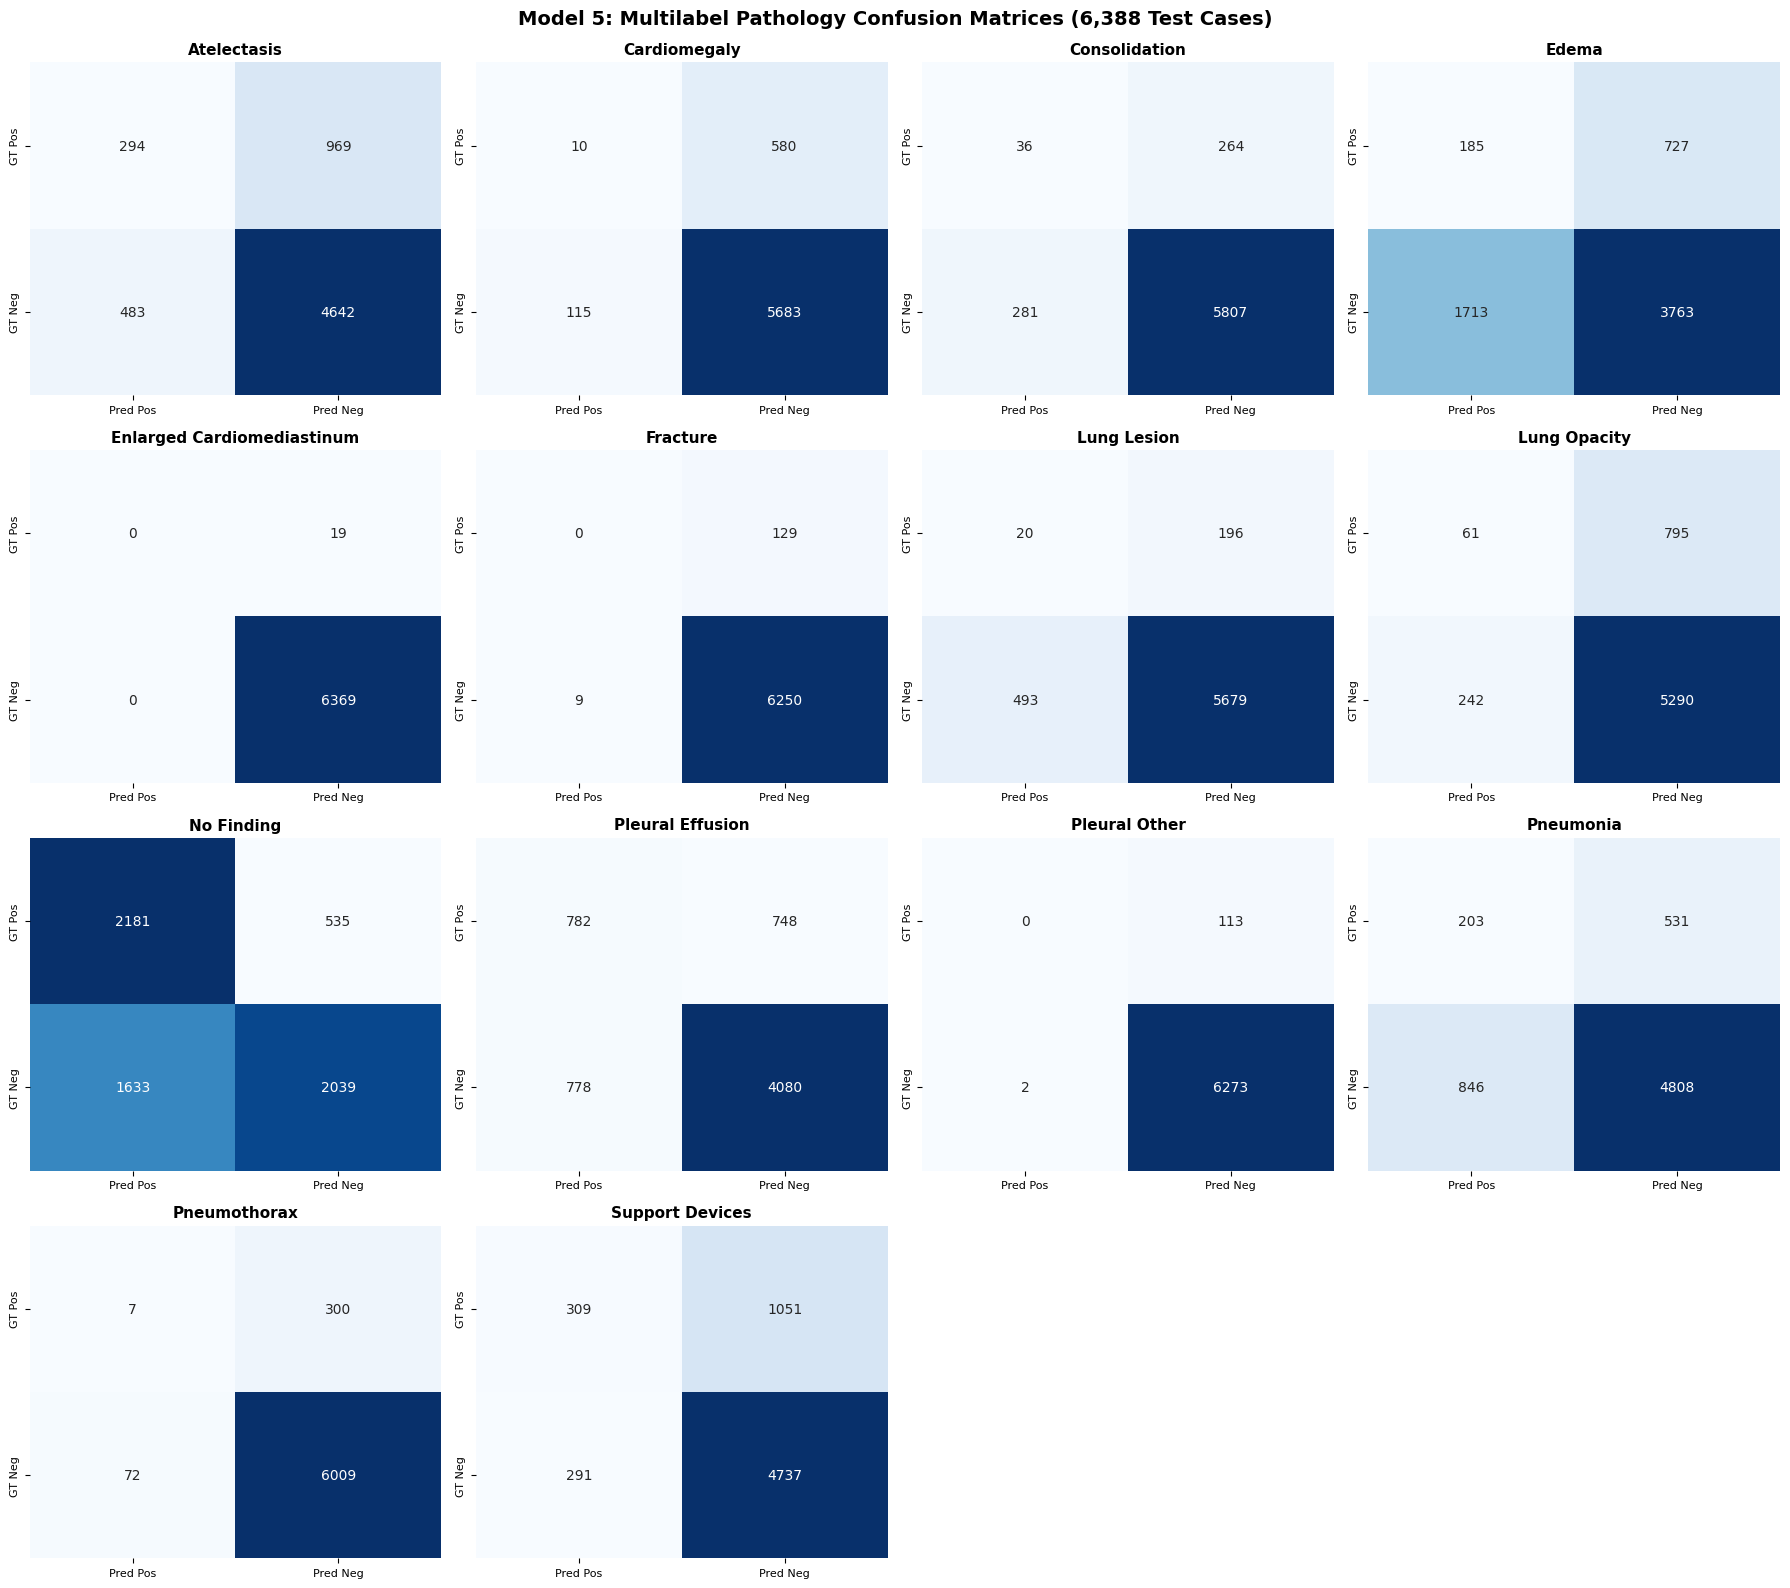


Evaluation completed successfully! All Model 5 artifacts saved to /kaggle/working/


In [2]:
# -------------------------------------------------------------------------
# 1. Standalone Model 5 Benchmark Evaluation (6,388 Test Samples)
#    Speed-Optimized Inference + Priority Best Checkpoint Loading
# -------------------------------------------------------------------------
import os, sys, gc, glob, time, json, math, random, re, torch
from pathlib import Path
import numpy as np
import pandas as pd
import torch.nn as nn
from tqdm.auto import tqdm

import nltk
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu, SmoothingFunction
from nltk.util import ngrams
from rouge_score import rouge_scorer
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, set_peft_model_state_dict

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Evaluation Compute Device: {device}", flush=True)

# -------------------------------------------------------------------------
# Locate Test Data and Model Checkpoints (Strict Priority to Best Checkpoint)
# -------------------------------------------------------------------------
print("Scanning mounted directories in /kaggle/input...", flush=True)
for root, dirs, files in os.walk("/kaggle/input"):
    if files:
        first_few = files[:5]
        print(f"  [Input Dir] {root} ({len(files)} files: {first_few})", flush=True)

best_ckpts = []
latest_ckpts = []

for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        f_lower = f.lower()
        full = os.path.join(root, f)
        if "model5_qwen_best.pt" in f_lower:
            best_ckpts.append(full)
        elif "model5_qwen_latest.pt" in f_lower:
            latest_ckpts.append(full)

# Strict priority: Always choose model5_qwen_best.pt (lowest val loss) over latest.pt
checkpoint_path = None
if best_ckpts:
    # Pick best with lowest validation loss if multiple exist
    best_meta = {"epoch": -1, "val_loss": float("inf")}
    for cand in best_ckpts:
        try:
            ckpt_dict = torch.load(cand, map_location="cpu")
            vl = ckpt_dict.get("val_loss", float("inf"))
            ep = ckpt_dict.get("epoch", 1)
            if vl < best_meta["val_loss"]:
                best_meta = {"epoch": ep, "val_loss": vl}
                checkpoint_path = cand
        except Exception:
            if checkpoint_path is None:
                checkpoint_path = cand
elif latest_ckpts:
    checkpoint_path = latest_ckpts[0]

features_spatial_path = None
manifest_path = None

for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        full = os.path.join(root, f)
        if f == "features_spatial_test.dat" and features_spatial_path is None:
            features_spatial_path = full
        elif f == "mimic_master_split_with_rag.csv" and manifest_path is None:
            manifest_path = full

print(f"Selected Checkpoint     : {checkpoint_path}", flush=True)
print(f"Found Test Spatial MMAP : {features_spatial_path}", flush=True)
print(f"Found Manifest CSV      : {manifest_path}", flush=True)

if not checkpoint_path or not features_spatial_path or not manifest_path:
    raise FileNotFoundError(
        "Missing required artifacts! Please ensure you added both the Data Prep dataset "
        "and the Model 5 Training run output via '+ Add Input'."
    )

df_all = pd.read_csv(manifest_path)
test_df = df_all[df_all["split"] == "test"].reset_index(drop=True)
num_test = len(test_df)
print(f"Loaded {num_test} test samples for benchmark evaluation.", flush=True)

# Spatial features were generated as float16 in Data Prep
test_spatial_mmap = np.memmap(
    features_spatial_path,
    dtype="float16",
    mode="r",
    shape=(num_test, 128, 768)
)

# Load Thresholds if available
thresholds_path = None
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        if f == "optimal_thresholds.json":
            thresholds_path = os.path.join(root, f)
            break

CHEXPERT_COLS = [
    "Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Enlarged Cardiomediastinum",
    "Fracture", "Lung Lesion", "Lung Opacity", "No Finding", "Pleural Effusion",
    "Pleural Other", "Pneumonia", "Pneumothorax", "Support Devices"
]

optimal_thresholds = {col: 0.5 for col in CHEXPERT_COLS}
if thresholds_path and os.path.exists(thresholds_path):
    with open(thresholds_path) as f:
        loaded_th = json.load(f)
        optimal_thresholds.update(loaded_th)
    print("Loaded class-specific optimal decision thresholds from JSON.", flush=True)
else:
    print("Using default 0.5 decision thresholds.", flush=True)

# -------------------------------------------------------------------------
# Load Architecture & Checkpoint
# -------------------------------------------------------------------------
MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

base_qwen = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    torch_dtype=torch.float16,
    device_map={"": 0},
    trust_remote_code=True
)
base_qwen = prepare_model_for_kbit_training(base_qwen)

ckpt = torch.load(checkpoint_path, map_location="cpu")
ckpt_epoch = ckpt.get("epoch", "unknown")
ckpt_loss = ckpt.get("val_loss", "unknown")
print(f"Loaded Checkpoint Metadata: Epoch={ckpt_epoch} | Validation Loss={ckpt_loss}", flush=True)

detected_rank = 32
for k, v in ckpt["lora_state"].items():
    if "lora_A" in k:
        detected_rank = v.shape[0]
        break

detected_alpha = detected_rank * 2
print(f"Auto-Detected LoRA Config: Rank r={detected_rank}, Alpha={detected_alpha}", flush=True)

peft_config = LoraConfig(
    r=detected_rank,
    lora_alpha=detected_alpha,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)
qwen_lora_model = get_peft_model(base_qwen, peft_config)

class MultiTaskQwenModel(nn.Module):
    def __init__(self, qwen_model, visual_dim=768, qwen_dim=2048, num_patches=128):
        super().__init__()
        self.qwen = qwen_model
        self.num_patches = num_patches
        self.qwen_dim = qwen_dim
        
        self.visual_projection = nn.Sequential(
            nn.Linear(visual_dim, qwen_dim),
            nn.LayerNorm(qwen_dim),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(qwen_dim, qwen_dim),
            nn.LayerNorm(qwen_dim)
        ).to(device=device)
        
        self.classifier = nn.Sequential(
            nn.Linear(visual_dim, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(512, 14)
        ).to(device=device)
        
    def build_4d_prefix_attention_mask(self, batch_size, seq_len, device, dtype, text_pad_mask=None):
        total_len = self.num_patches + seq_len
        mask = torch.full((total_len, total_len), -10000.0, dtype=dtype, device=device)
        mask[:self.num_patches, :self.num_patches] = 0.0
        for i in range(self.num_patches, total_len):
            mask[i, :i+1] = 0.0
            
        mask_4d = mask.unsqueeze(0).unsqueeze(0).expand(batch_size, 1, total_len, total_len).clone()
        if text_pad_mask is not None:
            pad_expanded = text_pad_mask.unsqueeze(1).unsqueeze(2)
            mask_4d[:, :, :, self.num_patches:] = mask_4d[:, :, :, self.num_patches:].masked_fill(pad_expanded == 0, -10000.0)
        return mask_4d

    @torch.no_grad()
    def generate_report(self, spatial_token, retrieved_report, max_new_tokens=45, repetition_penalty=1.15, max_rag_tokens=40):
        self.eval()
        self.qwen.config.use_cache = True
        
        if spatial_token.dim() == 2:
            spatial_token = spatial_token.unsqueeze(0)
            
        visual_embeds = self.visual_projection(spatial_token.float())
        
        if pd.isna(retrieved_report) or str(retrieved_report).strip().lower() in ["", "nan", "none"]:
            retrieved_clean = "Normal chest radiograph with no acute cardiopulmonary abnormality."
        else:
            retrieved_clean = str(retrieved_report).strip()
            
        rag_tokens = tokenizer.encode(retrieved_clean, add_special_tokens=False)[:max_rag_tokens]
        retrieved_clean = tokenizer.decode(rag_tokens, skip_special_tokens=True)
            
        # Pure Completion Prompt
        prompt_str = f"Context Findings: {retrieved_clean}\nFindings Impression:"
        prompt_enc = tokenizer(prompt_str, return_tensors="pt").to(device)
        prompt_ids = prompt_enc["input_ids"]
        prompt_embeds = self.qwen.get_input_embeddings()(prompt_ids)
        
        if visual_embeds.dtype != prompt_embeds.dtype:
            visual_embeds = visual_embeds.to(prompt_embeds.dtype)
            
        inputs_embeds = torch.cat([visual_embeds, prompt_embeds], dim=1)
        seq_len = prompt_ids.size(1)
        
        attention_mask_4d = self.build_4d_prefix_attention_mask(
            1, seq_len, spatial_token.device, inputs_embeds.dtype, prompt_enc["attention_mask"]
        )
        
        prefill_out = self.qwen(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask_4d,
            use_cache=True
        )
        past_key_values = prefill_out.past_key_values
        next_token_logits = prefill_out.logits[:, -1, :].clone()
        
        for token_id in set(prompt_ids[0].tolist()):
            if next_token_logits[0, token_id] > 0:
                next_token_logits[0, token_id] /= repetition_penalty
            else:
                next_token_logits[0, token_id] *= repetition_penalty
                
        curr_token = torch.argmax(next_token_logits, dim=-1, keepdim=True)
        generated_token_ids = []
        eos_id = tokenizer.eos_token_id
        if curr_token.item() != eos_id:
            generated_token_ids.append(curr_token.item())
        
        # Fast inference with smart sentence completion break
        for _ in range(max_new_tokens - 1):
            if curr_token.item() == eos_id:
                break
            step_embeds = self.qwen.get_input_embeddings()(curr_token)
            step_out = self.qwen(
                inputs_embeds=step_embeds,
                past_key_values=past_key_values,
                use_cache=True
            )
            past_key_values = step_out.past_key_values
            step_logits = step_out.logits[:, -1, :].clone()
            
            for token_id in set(generated_token_ids):
                if step_logits[0, token_id] > 0:
                    step_logits[0, token_id] /= repetition_penalty
                else:
                    step_logits[0, token_id] *= repetition_penalty
                    
            curr_token = torch.argmax(step_logits, dim=-1, keepdim=True)
            tok_id = curr_token.item()
            if tok_id == eos_id:
                break
            generated_token_ids.append(tok_id)
            
            # Smart Early-Stop: Break once the diagnostic impression is clinically completed (period after >= 10 tokens)
            if len(generated_token_ids) >= 10:
                recent_text = tokenizer.decode(generated_token_ids[-2:], skip_special_tokens=True)
                if "." in recent_text or "\n" in recent_text:
                    break
            
        pred_text = tokenizer.decode(generated_token_ids, skip_special_tokens=True).strip()
        return pred_text

model = MultiTaskQwenModel(qwen_lora_model).to(device)
model.visual_projection.load_state_dict(ckpt["visual_projection"])
model.classifier.load_state_dict(ckpt["classifier"])
set_peft_model_state_dict(qwen_lora_model, ckpt["lora_state"])
model.eval()
print(f"Model 5 loaded successfully from checkpoint: {checkpoint_path}", flush=True)

# -------------------------------------------------------------------------
# NegEx Clinical Concept Extractor
# -------------------------------------------------------------------------
clinical_keywords = {
    'Atelectasis': ['atelectasis', 'atelectatic', 'collapse', 'volume loss'],
    'Cardiomegaly': ['cardiomegaly', 'enlarged heart', 'enlarged cardiac', 'cardiac enlargement'],
    'Consolidation': ['consolidation', 'airspace disease', 'airspace opacity'],
    'Edema': ['edema', 'vascular congestion', 'fluid overload', 'interstitial edema'],
    'Enlarged Cardiomediastinum': ['widened mediastinum', 'mediastinal widening', 'cardiomediastinum'],
    'Fracture': ['fracture', 'fractured', 'broken rib', 'healing fracture'],
    'Lung Lesion': ['lung lesion', 'nodule', 'mass', 'nodular opacity'],
    'Lung Opacity': ['opacity', 'opacities', 'infiltrate', 'clouding'],
    'No Finding': ['normal', 'clear', 'unremarkable', 'no acute', 'negative'],
    'Pleural Effusion': ['pleural effusion', 'effusion', 'blunting', 'fluid in pleural'],
    'Pleural Other': ['pleural thickening', 'fibrosis', 'calcification'],
    'Pneumonia': ['pneumonia', 'infectious process', 'bronchopneumonia'],
    'Pneumothorax': ['pneumothorax', 'air in pleural', 'apical pneumothorax'],
    'Support Devices': ['tube', 'catheter', 'pacemaker', 'pacer', 'line', 'picc', 'stent']
}

negation_prefix_pattern = re.compile(r"\b(no|without|free of|negative for|absence of|denies|cleared of)\b\s*([\w\s]{0,35})$", re.IGNORECASE)
negation_suffix_pattern = re.compile(r"^([\w\s]{0,35})\s*\b(ruled out|is absent|resolved|excluded|unlikely|is not seen|not identified|has resolved|is clear)\b", re.IGNORECASE)

def detect_clinical_presence(text, keywords):
    text_lower = text.lower()
    for kw in keywords:
        matches = [m.start() for m in re.finditer(re.escape(kw), text_lower)]
        for match_idx in matches:
            prefix_window = text_lower[max(0, match_idx - 35):match_idx]
            suffix_window = text_lower[match_idx + len(kw):min(len(text_lower), match_idx + len(kw) + 35)]
            if not negation_prefix_pattern.search(prefix_window) and not negation_suffix_pattern.search(suffix_window):
                return 1
    return 0

# -------------------------------------------------------------------------
# Test Benchmark Loop Execution (Fast & Safe)
# -------------------------------------------------------------------------
smooth = SmoothingFunction().method1
rouge_evaluator = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

results = []
bleu1_s, bleu2_s, bleu3_s, bleu4_s = [], [], [], []
rouge1_s, rouge2_s, rougeL_s = [], [], []
distinct2_s = []

gt_pathology_list = []
pred_pathology_list = []
corpus_refs = []
corpus_hyps = []

start_eval_time = time.time()
print(f"Starting Benchmark Evaluation on all {num_test} test cases...", flush=True)

for i in range(num_test):
    row = test_df.iloc[i]
    orig_idx = int(row["orig_split_idx"])
    spatial_t = torch.from_numpy(np.array(test_spatial_mmap[orig_idx])).to(device)
    retrieved_r = row["retrieved_report"]
    gt_text = str(row["report"]).strip() if pd.notna(row["report"]) else "Normal chest radiograph."
    
    pred_text = model.generate_report(spatial_t, retrieved_r, max_new_tokens=45, repetition_penalty=1.15, max_rag_tokens=40)
    
    ref_tok = [nltk.word_tokenize(gt_text.lower())] if gt_text else [[""]]
    hyp_tok = nltk.word_tokenize(pred_text.lower()) if pred_text else [""]
    
    corpus_refs.append(ref_tok)
    corpus_hyps.append(hyp_tok)
    
    b1 = sentence_bleu(ref_tok, hyp_tok, weights=(1, 0, 0, 0), smoothing_function=smooth)
    b2 = sentence_bleu(ref_tok, hyp_tok, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth)
    b3 = sentence_bleu(ref_tok, hyp_tok, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smooth)
    b4 = sentence_bleu(ref_tok, hyp_tok, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth)
    
    rouge_res = rouge_evaluator.score(gt_text, pred_text)
    r1 = rouge_res['rouge1'].fmeasure
    r2 = rouge_res['rouge2'].fmeasure
    rL = rouge_res['rougeL'].fmeasure
    
    bleu1_s.append(b1)
    bleu2_s.append(b2)
    bleu3_s.append(b3)
    bleu4_s.append(b4)
    rouge1_s.append(r1)
    rouge2_s.append(r2)
    rougeL_s.append(rL)
    
    if len(hyp_tok) >= 2:
        bigrams = list(ngrams(hyp_tok, 2))
        distinct2_s.append(len(set(bigrams)) / len(bigrams))
    else:
        distinct2_s.append(1.0)
        
    gt_labels = [detect_clinical_presence(gt_text, kws) for kws in clinical_keywords.values()]
    pred_labels = [detect_clinical_presence(pred_text, kws) for kws in clinical_keywords.values()]
    
    gt_pathology_list.append(gt_labels)
    pred_pathology_list.append(pred_labels)
    
    results.append({
        "study_id": row["study_id"],
        "dicom_id": row["dicom_id"],
        "ground_truth": gt_text,
        "prediction": pred_text,
        "bleu1": round(b1, 4),
        "bleu4": round(b4, 4),
        "rougeL": round(rL, 4)
    })
    
    if (i + 1) % 100 == 0 or (i + 1) == num_test:
        elapsed = (time.time() - start_eval_time) / 60.0
        pct = ((i + 1) / num_test) * 100.0
        eta = (elapsed / (i + 1)) * (num_test - (i + 1))
        avg_b1 = np.mean(bleu1_s)
        print(f"[Test Eval {i+1:04d}/{num_test} ({pct:5.1f}%)] Elapsed: {elapsed:.1f}m | ETA: {eta:.1f}m | Avg BLEU-1: {avg_b1:.4f}", flush=True)

# -------------------------------------------------------------------------
# Benchmark Aggregations
# -------------------------------------------------------------------------
y_true = np.array(gt_pathology_list)
y_pred = np.array(pred_pathology_list)

pathology_names = list(clinical_keywords.keys())
chexpert_gt_counts = np.array([test_df[col].sum() for col in pathology_names])
core_indices = [i for i, cnt in enumerate(chexpert_gt_counts) if cnt >= 150]

cb1 = corpus_bleu(corpus_refs, corpus_hyps, weights=(1, 0, 0, 0), smoothing_function=smooth)
cb2 = corpus_bleu(corpus_refs, corpus_hyps, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth)
cb3 = corpus_bleu(corpus_refs, corpus_hyps, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smooth)
cb4 = corpus_bleu(corpus_refs, corpus_hyps, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth)

summary_metrics = {
    "Model": "Model 5 (RAD-DINO + Qwen-2.5-3B + Completion Prompting + ASL)",
    "Test_Samples": len(results),
    "Sentence BLEU-1": round(float(np.mean(bleu1_s)), 4),
    "Sentence BLEU-2": round(float(np.mean(bleu2_s)), 4),
    "Sentence BLEU-3": round(float(np.mean(bleu3_s)), 4),
    "Sentence BLEU-4": round(float(np.mean(bleu4_s)), 4),
    "Corpus BLEU-1 (NIST)": round(float(cb1), 4),
    "Corpus BLEU-2 (NIST)": round(float(cb2), 4),
    "Corpus BLEU-3 (NIST)": round(float(cb3), 4),
    "Corpus BLEU-4 (NIST)": round(float(cb4), 4),
    "ROUGE-1": round(float(np.mean(rouge1_s)), 4),
    "ROUGE-2": round(float(np.mean(rouge2_s)), 4),
    "ROUGE-L": round(float(np.mean(rougeL_s)), 4),
    "Distinct-2": round(float(np.mean(distinct2_s)), 4),
    "Clinical_Macro_F1_All14": round(float(f1_score(y_true, y_pred, average='macro', zero_division=0)), 4),
    "Clinical_Macro_F1_Core10": round(float(f1_score(y_true[:, core_indices], y_pred[:, core_indices], average='macro', zero_division=0)), 4),
    "Clinical_Micro_F1": round(float(f1_score(y_true, y_pred, average='micro', zero_division=0)), 4),
    "Clinical_Micro_Precision": round(float(precision_score(y_true, y_pred, average='micro', zero_division=0)), 4),
    "Clinical_Micro_Recall": round(float(recall_score(y_true, y_pred, average='micro', zero_division=0)), 4)
}

print("\n" + "="*80, flush=True)
print("OVERALL BENCHMARK: Model 5 (RAD-DINO + Qwen-2.5-3B + Completion Prompting + ASL)")
print("="*80, flush=True)
for k, v in summary_metrics.items():
    if k not in ["Model", "Test_Samples"]:
        print(f"{k:<30} | {v}", flush=True)
print("="*80 + "\n", flush=True)

# -------------------------------------------------------------------------
# Per-Pathology Breakdown
# -------------------------------------------------------------------------
pathology_stats = []
print("="*110, flush=True)
print("PER-PATHOLOGY CLINICAL BREAKDOWN: Model 5 (Proposal N >= 150 Threshold Flagging)", flush=True)
print("="*110, flush=True)

for i, name in enumerate(pathology_names):
    cm = confusion_matrix(y_true[:, i], y_pred[:, i], labels=[1, 0])
    tp = int(cm[0, 0])
    fn = int(cm[0, 1])
    fp = int(cm[1, 0])
    tn = int(cm[1, 1])
    
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    
    cnt = int(test_df[name].sum())
    flag = "[Low Sample (N < 150)]" if cnt < 150 else "[OK]"
    
    pathology_stats.append({
        "Pathology": name, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision": round(prec, 4), "Recall": round(rec, 4), "F1": round(f1, 4),
        "CheXpert_GroundTruth_Count": cnt, "Status": flag
    })
    print(f"{name:<26} | {tp:<5} | {fp:<5} | {fn:<5} | {tn:<5} | {prec:<7.4f} | {rec:<7.4f} | {f1:<7.4f} | {flag}", flush=True)

# -------------------------------------------------------------------------
# 14-Panel Heatmap Visualization
# -------------------------------------------------------------------------
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for idx, col in enumerate(pathology_names):
    cm = confusion_matrix(y_true[:, idx], y_pred[:, idx], labels=[1, 0])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
                xticklabels=["Pred Pos", "Pred Neg"],
                yticklabels=["GT Pos", "GT Neg"])
    axes[idx].set_title(col, fontsize=11, fontweight="bold")
    axes[idx].tick_params(axis="both", labelsize=8)

for j in range(len(pathology_names), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Model 5: Multilabel Pathology Confusion Matrices (6,388 Test Cases)", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig("/kaggle/working/pathology_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

pd.DataFrame(results).to_csv("/kaggle/working/model5_test_predictions.csv", index=False)
pd.DataFrame(pathology_stats).to_csv("/kaggle/working/model5_pathology_breakdown.csv", index=False)
with open("/kaggle/working/model5_test_metrics.json", "w") as f:
    json.dump(summary_metrics, f, indent=2)

print("\nEvaluation completed successfully! All Model 5 artifacts saved to /kaggle/working/", flush=True)
